<a href="https://colab.research.google.com/github/Madmins07/Madmins07/blob/main/kdag_Task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> # ***Problem Statement***

> In modern urban planning, the efficient design of road networks is crucial for fostering
connectivity and sustainable development. Night-time satellite imagery offers a unique
perspective, with illuminated areas often indicative of urban centers. In this task, you have to
develop an algorithm to extract the cities from this satellite image.
You've got a simulated night-time satellite image, a grid of 64x64 squares with white dots
representing places where there's light. Your job is to create an algorithm that can find these dots
and locate the cities on the 64x64 grid by clustering them.
After identifying cities through clustering, calculate the distances between them using the center
point of cities. Present the distances in a clear format, such as a table.

> Link for the images used for test purpose :- https://drive.google.com/drive/folders/1g3gvgRkj5yLfvtJ64JnaZd6hqtklSPkC

> __IMPORTANT NOTE__



1.   Making sure that the images are labelled accordingly as "picx.png" where x is the picture's number

2.  Making sure that the images and the notebook are being operated in the same working directory.

> ### **Importing all the Libraries**

In [ ]:
import cv2
import matplotlib.pyplot as plt
import random
import numpy as np
import math
import pandas as pd
from tabulate import tabulate

> # **Function Definitions**

In [ ]:
# Function to initialise x and y coordinates of k centroids
def initialise(image,k):
  x_max , y_max = image.shape[0],image.shape[1]

  cent = [] # Storing all the centres in an array cent as list elements([x,y])

  for j in range(k):

    # Generating random values of x and y
    x = random.randint(0,x_max)
    y = random.randint(0,y_max)

    cent.append([x,y]) # Appending the randomly generated centers
  return cent

In [ ]:
# Function to assign points with their nearest centroid
def near_point(cent,k,x,y):
  d = np.zeros((x.shape[0],k))

  # Finding eucledian distance between every point wrt every centroid
  for idx,j in enumerate(cent):
    dist = (x - j[0])**2 + (y - j[1])**2
    d[:,idx]=(dist**0.5)

  near_pt = np.zeros(d[0].shape)
  near_pt = np.argmin(d,axis = 1) # Finding the least distance of a point wrt the k centroid

  poss = []

  # Assigning every point wrt their nearest centroid
  for i in range(len(cent)):
    posx = x[near_pt == i]
    posy = y[near_pt == i]

    poss.append([posx,posy]) # Appending the list in poss

  return near_pt,poss

In [ ]:
# Function to update the centroid's coordinates
def new_g(poss,cent):
  new_cent = [] # Storing the new centroid in an array new_cent
  for idx,j in enumerate(poss):
    if j[0].shape[0] != 0:
      g = [j[0].mean(), j [1].mean()] # Taking the mean of the all the points nearest to the respective centroid
    else:
      g = [cent[idx][0],cent[idx][1]]
    new_cent.append(g) # Appending the new coordinates of the centroid

  return new_cent

In [ ]:
# Function to plot image with centroids having coordinates stores in cent and points nearest to the centroid stored in poss
def plut(image,cent,poss):

  # Defining 14 different colours meaning we can use a maximum value of k=14
  colors=['blue','green','red','orange','purple','brown','yellow','aqua','indigo','crimson','cyan','magenta','pink','olive']
  plt.figure()
  plt.imshow(image, cmap='gray')

  # Plotting the image wrt the new coordinates of the centroid
  for idx,j in enumerate(cent):
    plt.plot(poss[idx][1],poss[idx][0],'o', color=colors[idx]) # Defining colours of nearest points as circles
    plt.plot([j[1],], [j[0],],'+', color=colors[idx]) # Defining colours of centroids as plus sign
  plt.show()

In [ ]:
# Function to determine the cost, that is gettting the sum of all distances of points from their respective centroids
def cost(poss,cent):
  cost = 0
  for idx,j in enumerate(cent):

    # Taking the sum of all the eucledian distance between the point wrt their centroids and summing all up
    cost += (((poss[idx][0] - j[0])**2 + (poss[idx][1] - j[1])**2)**0.5).sum()

  return cost

In [ ]:
# Function to find the least cost for value oa given of k
def cost_check(final_cents, image,k):
  main_cent = [] # Array to store final coordinates
  min_cost = np.inf # Setting initial cost to infinity for comparison sake

  # Getting costs for different centers
  for i in final_cents:
    cst = cost(i[1],i[0])

    # Storing the optimal cost and centers
    if cst < min_cost:
      min_cost = cst
      main_cent = i

  # Printing the optimal cost and plotting it
  print(f"\nPlotting the convergent optimal cluster for k={k}")
  print(f"The minimum cost for value of k={k} is:-",min_cost)
  plut(image,main_cent[0], main_cent[1])
  return min_cost, main_cent[0]

In [ ]:
# Function to find optimal clusters for a given k value
def cluster(k,image,x,y):
  final_cents = []

  # IMP NOTE:- We can run as many as possible 50 different initialisations is used as a base benchmark
  # Running 50 randomised initialisations for clustering
  for i in range(50):

    # Initialising centers
    cent = initialise(image,k)

    # Near points and points matching for each center
    near_pt, poss = near_point(cent,k,x,y)

    # Setting last center value as empty list
    last_cent = []

    # Iterating while current and last center don't have the same value, that is till convergence
    while(last_cent != cent):
      last_cent = cent.copy()

      # Getting the new centroid value annd setting it as the new center
      cent = new_g(poss,cent)
      near_pt, poss = near_point(cent,k,x,y)

    # Appending the final value of center to the list of final centers of all iterations
    final_cents.append([cent,poss])

  # Finding least cost values for all the centers and returning it
  return cost_check(final_cents, image,k)

In [ ]:
# Same function as cluster but here we generate stepwise plots till we arrive convergence and then print the plot of the optimal value of k
def cluster_itr(k,image,x,y,iterations):
  final_cents = []

  # Iterations is the no. of times we use the same value of k and reinitialise the centers and plot every plot till convergence
  for i in range(iterations):
    print(f"\nIteration number {i+1}\n")
    cent = initialise(image,k)
    near_pt, poss = near_point(cent,k,x,y)
    print(f"Initial cost at iteration number {i+1} is:- ",cost(poss,cent))
    plut(image,cent,poss)
    last_cent = []

    while(last_cent != cent):
      last_cent = cent.copy()

      cent = new_g(poss,cent)
      near_pt, poss = near_point(cent,k,x,y)
      print(f"\nNew cost at iteration number {i+1}:-",cost(poss,cent))
      plut(image,cent,poss) # Plotting all subsequent plots till convergence


    final_cents.append([cent,poss])
  print(f"Final optimal cost for k={k} is:-",cost_check(final_cents, image,k)[0])

In [ ]:
# Finding optimal value of k, given costs for all the different values of k
def min_k(costs,avg_cost):
  # Initialising cost of point 1 as c1 and for point 2 as c2 so as to find the slope between first 2 points and its angle
  c1 = costs[0]
  c2 = costs[1]
  sl = (c2 - c1)/avg_cost
  ang1 = -abs(math.atan(sl))

  # Setting opt as 0,0 to store the max angle difference and the optimal k value later
  opt = [0,0]

  # Finding consecutive point costs and assigning them to c1,c2, finding slope and angle of slope
  for i in range(len(costs)-2):
    c1 = costs[i+1]
    c2 = costs[i+2]
    sl = (c2 - c1)/avg_cost
    ang2 = -abs(math.atan(sl))

    # Checking if angle difference is larger than current max angle difference and changing opt. if so
    if opt[0] < ang2 - ang1:
      opt[0] = ang2 - ang1
      opt[1] = i + 2

    else:
      break

    # Setting last angle equal to current for the next iteration
    ang1 = ang2

  # Returning the optimal value of k
  return opt[1]

In [ ]:
# Function to repeat the clustering process for different number of clusters to ultimately get the optimal number
def check_k(image,x,y):

  # Set costs and main_cents as empty, to store costs and main centers values
  costs = []
  main_cents = []

  # To calculate avg. cost
  total_cost = 0
  for i in range(14):
    cost, main_cent  = cluster(i+1,image,x,y)
    main_cents.append(main_cent)
    costs.append(cost)
    total_cost += cost

  # Calculating avg. cost
  avg_cost = total_cost/14
  print()

  # Plotting the graph of number of clusters vs cost
  plt.plot(np.linspace(1,14,14),costs)
  plt.xlabel("No. of clusters(k)")
  plt.ylabel("Cost")
  print("\nPlotting graph of cost vs k(elbow method):-\n")
  plt.show()

  # Getting final optimised k value and printing it
  k_final = min_k(costs,avg_cost)
  print()
  print("Final optimal value of k is : ",k_final)
  # Getting the cooridnates of the center for optimal k from main_cents
  cent_final = main_cents[k_final-1]
  # Converting it to a numpy array, to calculate pair distances
  cent_final = np.array(cent_final)

  # Variable to store distances
  dists = []

  # Calculating distance values with respect to each center and appending them to dists
  for i in cent_final:
    cent_new = (cent_final - i)
    dist = (cent_new[:,0]**2 + cent_new[:,1]**2)**0.5
    dists.append(dist)

  # Getting individual distances point-pairwise and appending to ans to display via tables
  ans=[]
  for i in range(k_final):
    try:
      for j in range(i+1,k_final):
        ans.append([f"Cluster {i+1} and {j+1}",dists[i][j]])
    except:
      pass

  # Using an index variable for the column storing serial number
  index = list(range(1, len(ans) + 1))

  # Using df to tabulate data
  df = pd.DataFrame(ans, columns=['Cluster Combinations', 'Respective Distances'],index=index)
  df_centered = df.rename(columns={col: col.center(10) for col in df.columns})

  # Finally clustering again for k_final,x,y
  cluster(k_final,curr_image,x,y)

  # Printing the values of optimal k, centers and their individual pair-wise distances

  print("Center positions for final value of k is:\n",cent_final)
  print(tabulate(df_centered, headers='keys', tablefmt='grid'))

  return k_final

> # **Loading images and Plotting them respectively**

In [ ]:
image1 = cv2.imread('pic1.png')
image1 = image1[:,:,0]
plt.imshow(image1, cmap='gray')

In [ ]:
image2 = cv2.imread('pic2.png')
image2 = image2[:,:,0]
plt.imshow(image2, cmap='gray')

In [ ]:
image3 = cv2.imread('pic3.png')
image3 = image3[:,:,0]
plt.imshow(image3, cmap='gray')

In [ ]:
image4 = cv2.imread('pic4.png')
image4 = image4[:,:,0]
plt.imshow(image4, cmap='gray')

> # **Clustering, Elbow method, Identification of optimal value of k, Stepwise iteration at optimal value of k**

> ***Imp note :-*** Use the variable curr_image to change images. Default value is set as image 1, use image2, image3 and image4 for corresponding plots

In [ ]:
curr_image = image4
x,y=np.where(curr_image == 255)



```
# This is formatted as code
```

> ## ***Running to find the optimal value of k***

In [ ]:
optimal_k=check_k(curr_image,x,y)

> ## ***After finding the optimal value of k, we can plot the final clustered image and its cost***


Plotting the convergent optimal cluster for k=2
The minimum cost for value of k=2 is:- 503.0060949273706


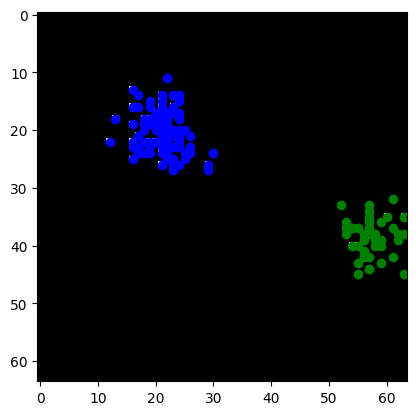

(503.0060949273706,
 [[20.329113924050635, 21.075949367088608], [38.44736842105263, 57.5]])

In [ ]:
cluster(optimal_k,curr_image,x,y)

> ***Function to see all subsequent changes to the plot from initialisation to convergence***

In [ ]:
# No. of times the centers are initialised to convergence is the value of the iterations variable

iterations=4 # Higher the value of iterations, higher is the chance to get a plot that will converge

cluster_itr(optimal_k,curr_image,x,y,iterations) # In the end out of all the iterations it will plot the optimal cost plot